# Generalized QSP with supplied angles
Planned companion. The five code cells are prepared but unexecuted. They construct a polynomial of an explicit unitary signal; no inverse angle compiler or full Hamiltonian simulation is claimed.


In [1]:
import sys, importlib.util
from pathlib import Path
assert sys.version_info[:3] == (3, 12, 14)
root = Path.cwd()
script = root / 'generate_simulation_gqsp.py'
if not script.is_file():
    script = root / 'scripts/generate_simulation_gqsp.py'
loader = importlib.util.spec_from_file_location('gqsp_notebook_producer', script)
producer = importlib.util.module_from_spec(loader)
sys.modules[loader.name] = producer
loader.loader.exec_module(producer)
gqsp = producer.gqsp
print('Given-angle prototype; numerical results need this notebook to execute.')
snapshot = producer.source_snapshot()
print('Input source commit:', snapshot['source_commit'])


Given-angle prototype; numerical results need this notebook to execute.
Input source commit: 953262e3d810a90ff3c7e32c4dd3000e9e6ecad5


In [2]:
case = producer.CASE_VECTOR[1]
spec, rotations = producer.case_spec(case)
print(case)
print('These are supplied rotations, not an inverse phase fit.')


{'id': 'complex-degree1', 'n': 1, 'y_pi': ['0'], 'z_pi': ['1/4'], 'chi_pi': '1/4', 'rotations_pi': [['1/4', '0', '0'], ['1/4', '0', '1/2']], 'input': 'plus_i', 'simulate': True}
These are supplied rotations, not an inverse phase fit.


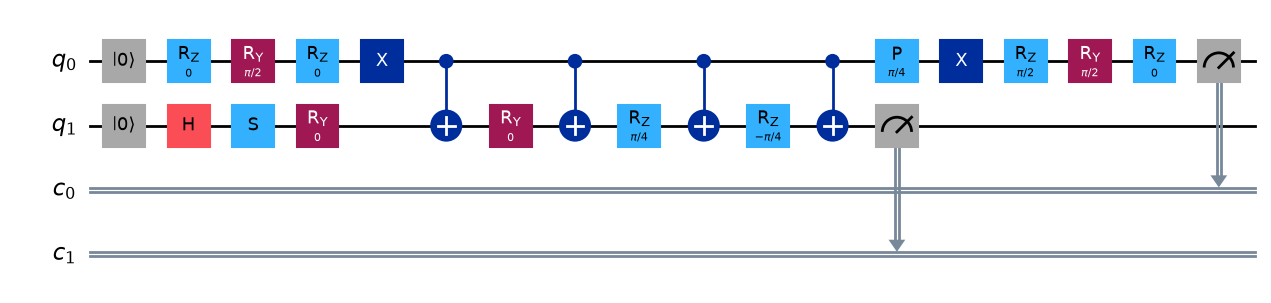

In [3]:
import matplotlib.pyplot as plt
trial = gqsp.build_measured_trial(spec, rotations, case['input'])
figure = trial.draw('mpl', cregbundle=False)
display(figure)
plt.close(figure)


In [4]:
report = producer.small_report(spec, rotations, case['input'], snapshot)
p, q = gqsp.polynomial_coefficients(rotations)
print('ascending P coefficients:', p)
print('ascending Q coefficients:', q)
print(report)
print('The tiny comparisons are numerical; physical synthesis and a formal proof are uncomputed.')


ascending P coefficients: ((-0.35355339059327373-0.3535533905932737j), (0.35355339059327384-0.3535533905932738j))
ascending Q coefficients: ((0.3535533905932738+0.35355339059327373j), (0.3535533905932738-0.35355339059327373j))
{'status': 'numerical_small_checks_passed', 'evidence': 'bounded floating-point comparison; no interval or formal certificate', 'p_block_error': 1.2412670766236366e-16, 'q_block_error': 1.1102230246251565e-16, 'unitarity_error': 3.3306690738754696e-16, 'scalar_product_error': 1.415262216750919e-16, '17_point_circle_identity_residual': 2.220446049250313e-16, 'prepared_vector_error': 7.850462293418876e-17, 'actual_reset_program_error': 1.3877787807814457e-16, 'accepted_probability': 0.2499999999999999, 'joint_readout_probabilities_lsb_ancilla': [0.2499999999999999, 0.25, 1.232595164407831e-32, 0.4999999999999999], 'conditional_state_available': True, 'measurements': 2, 'resets': 2, 'literal_finite_shot_sampling_performed': False}
The tiny comparisons are numerical;

In [5]:
rows = []
for n in (1, 2, 3, 8, 64):
    template = producer.CASE_VECTOR[6]
    local_case = {**template, 'n': n, 'input': 'plus_i' if n == 1 else 'plus_i_x'}
    local_spec, local_rotations = producer.case_spec(local_case)
    generated = gqsp.build_measured_trial(local_spec, local_rotations, local_case['input'])
    rows.append({'n': n, 'degree': len(local_rotations)-1, 'wires': generated.num_qubits, 'instructions': len(generated.data), 'scope': 'generation/counts only'})
print(rows)
print('No dense simulation ran for this size slice; degree is fixed and the unitary signal changes with n.')
producer.recheck_snapshot(snapshot)


[{'n': 1, 'degree': 6, 'wires': 2, 'instructions': 93, 'scope': 'generation/counts only'}, {'n': 2, 'degree': 6, 'wires': 3, 'instructions': 246, 'scope': 'generation/counts only'}, {'n': 3, 'degree': 6, 'wires': 4, 'instructions': 398, 'scope': 'generation/counts only'}, {'n': 8, 'degree': 6, 'wires': 9, 'instructions': 1158, 'scope': 'generation/counts only'}, {'n': 64, 'degree': 6, 'wires': 65, 'instructions': 9670, 'scope': 'generation/counts only'}]
No dense simulation ran for this size slice; degree is fixed and the unitary signal changes with n.
